# Case Study 8 — Price Elasticity and Discount Efficacy: Is the Sale Really a Sale, and Do Discounts Pay?

**Priority:** ★★ Good to have · **Reference:** Case Study 8 — *Marketplace price monitoring / discount efficacy on Flipkart (outside academic analysis)* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Pricing and Promotions, Category Heads, Finance, Growth
**Evidence level:** **Weak.** The only public source is an outside study of public Flipkart prices; no company pricing method is documented. See section 2.
**Data:** ⚠️ **SYNTHETIC** (D-08-01). Price and unit data are confidential; this is a calibrated simulation with a hidden true elasticity per product.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs08_price_elasticity_discounts.ipynb`

## 0. Executive Summary for Business

*(Simulated SKU-week data with a hidden true elasticity. The evidence for this case is **weak**: the only public source is an outside academic study of public Flipkart sale prices on mobile phones, with no sales data and no company method. This is an interview-standard solution on simulated data, not a reproduction of any company's pricing system.)*

- **The question:** how much do sales respond to price, is a "% off" badge a real sale, and do platform-funded discounts pay for themselves?
- **A naive regression says demand barely reacts to price.** Pooled OLS gives an elasticity of **−0.24** (95% CI −0.29 to −0.19) against a hidden truth of **−1.97**. Prices are not set at random, so the naive slope is wrong by 1.7. The **randomised price test** (120 SKUs, 918 SKU-weeks) gives **−2.00** (CI −2.30 to −1.70) and **instrumental variables** on the supplier-cost index gives **−1.94** (CI −2.05 to −1.83; first-stage F = 5,658).
- **Adding obvious controls is not enough.** Fixed effects plus a sale flag and competitor price give **−1.51**, still 0.47 too close to zero (IV differs from it, Hausman-type z = −9.2). SKU fixed effects alone land at −1.99, but that looks like two opposite biases cancelling in this design, not a method to trust.
- **Every category is price-elastic; mobiles least.** IV elasticities run from **−1.41 for mobiles** (CI −1.76 to −1.06) to **−2.74 for mobile accessories**; all eight differ from −1 after Holm correction (mobiles p = 0.024) and all eight CIs cover the truth.
- **Promotions borrow from the following weeks.** Units are **+64%** in the promotion week (CI +61% to +68%), then **−16%** and **−8%** in the next two weeks. The estimated three-week net effect is **+13.6%** a week on average (CI +12.3% to +14.9%), but the true value is +24.2%, so this event study overstates the dip. The direction is right and the size is not exact.
- **The badge is a poor test of a real sale.** **32.6%** of SKU-weeks show 30% or more off MRP but only **10.7%** are real sales (15% or more below the SKU's recent median price). Only **23.8%** of badge weeks are real; kappa is **0.24** (CI 0.21 to 0.27). Every false badge sits on an inflated-MRP SKU.
- **Classifier (the paper's task):** with the sale-week flag, accuracy is **92.0%** against **89.4%** for "never significant" (PR-AUC 0.45 against 0.11 prevalence). With product features and price only, the models **only match the majority baseline** (89.4%, F1 = 0). The paper's 91.11% is not tested here.
- **Money (assumed economics):** at a 17% take rate with the platform funding 10% of the price cut, **all eight categories lose money on a promotion** (three-week profit multiplier 0.91 to 0.99). Stopping platform-funded promotions is worth about **₹136 crore a year** (₹106 to ₹160 crore) on ₹30,000 crore of GMV. If sellers fund the discount, six of eight categories are about break-even or slightly positive.

## 1. The Problem in Simple English

A marketplace runs discounts all year and especially in sale weeks. Three plain questions follow.

1. **How much do sales rise when price falls?** That is **price elasticity**: a 10% price cut that lifts units by 18% means an elasticity of about −1.8. It decides which categories deserve discounts.
2. **Is the sale really a sale?** Many listings show a large "% off" against an inflated list price (MRP). A shopper or an analyst needs a test of whether the discount is **real** (against what the item normally sells for).
3. **Does a discount pay for itself?** Extra units in the sale week are partly **pulled forward** from the weeks after, and the platform often funds part of the discount.

The trap in the first question is that **prices are not set at random**. Sellers change prices because demand moved, cost moved or a rival moved. A naive "units against price" regression on this data can show elasticity near zero or even the wrong sign, and then the business concludes "discounts do not work" or "any discount works". This notebook shows how large that error is, and how to remove it with fixed effects, an instrument and a randomised price test.

## 2. Reference from the Case File

### (a) What is documented — *weak evidence*

| Item | Documented fact (from the reference file) |
|---|---|
| Source | One outside academic paper: arXiv 2005.04612 (Singhania et al., 2020), a study of public **Flipkart Summer Sale** data on **mobile phones** |
| Question | Whether a "sale" discount is genuinely significant; can product features and original price predict that |
| Method | A support vector machine classifier; metric: accuracy (the authors claim "accuracy of 91.11%" and that very few phones have a significant discount) |
| Not documented | Dataset size and fields, the definition of "significant", features, validation, any sales or elasticity data |
| Company evidence | **None.** No Flipkart or Amazon India engineering source on price optimisation was found. This is a buyer-side view, not a company pricing engine |

> **Plain statement:** public method detail is thin. This notebook is an **interview-standard solution on simulated data**, not a reproduction of any company's pricing system, and the paper's 91.11% is the authors' own claim that we do not reproduce or test.

### (b) What *we* simulate and add

| Item | Our choice (all assumptions) |
|---|---|
| Data | 600 SKUs in 8 categories × 52 weeks (≈ 31,000 SKU-weeks), prices, units, MRP, a competitor price, a supplier-cost index, 4 sale-event weeks |
| Hidden truth | A true elasticity per SKU (category means from −1.4 for mobiles to −2.6 for accessories), post-promotion demand dips, price endogeneity, and 30% of SKUs with an inflated MRP |
| Randomised test | 120 SKUs, 8 weeks, price −10% / 0% / +10% drawn at random per SKU-week |
| Statistics added | Ladder of elasticity estimators (naive, fixed effects, controls, **instrumental variables**, experiment), Hausman-type test, category elasticities with **Holm**, experiment analysis with **power**, **event study** of promotion lift and the dip, displayed vs true discount agreement (**Cohen's kappa**, **McNemar**), classifier vs majority baseline |
| ML | The paper's task: classify "significant discount" with SVM, logistic regression and gradient boosting, judged against the majority baseline |

### (c) How the industry uses this

Elasticity estimates feed promotion planning, price-matching rules and markdowns. Interview questions on this topic are about **identification** (why naive regressions mislead), log-log models, instruments and experiments, the pull-forward dip, MRP inflation, and constrained optimisation (a discount budget). Public company detail is limited, so the interview answer rests on general method.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Where should we spend discount money, and how do we tell a real sale from a cosmetic one? |
| Analytical | What is the causal price elasticity by category, how much of a promotion's lift survives the post-promotion dip, and can a classifier flag significant discounts better than "never significant"? |

**Hypotheses**
- **H1:** H0: the naive pooled elasticity equals the randomised-experiment elasticity (and fixed-effects OLS equals IV: Hausman-type bootstrap test).
- **H2:** H0: a category's elasticity is −1, so a price change leaves revenue unchanged (IV; Holm across 8 categories).
- **H3:** H0: the net effect of a promotion on units over the promotion week plus the next two weeks is zero (event study; cluster bootstrap).
- **H4:** H0: the displayed-discount badge (≥ 30% off MRP) agrees with a true significant discount (≥ 15% below the SKU's trailing 8-week median price) no better than chance (Cohen's kappa; McNemar).
- **H5:** H0: a classifier of significant discounts is no better than predicting "never significant" (McNemar on the same SKU-weeks).

**Primary metrics:** elasticity (log-log slope), net promotion lift, kappa, PR-AUC. **Business metric:** platform contribution per ₹ of discount, in ₹ crore a year.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, average_precision_score, cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian marketplace price and unit data | **None with units.** Public price scrapes exist (the paper above used public Flipkart prices) but show no sales, so elasticity cannot be estimated from them. |
| **Decision** | Synthetic SKU-week panel with hidden true elasticity, so that every estimator can be checked against the truth (D-08-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs08.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 8 (marketplace price elasticity and discount efficacy)
============================================================================================
THIS DATA IS SYNTHETIC. No marketplace publishes its price and unit data, and the evidence for this case is weak:
the only public source (arXiv 2005.04612, Singhania et al. 2020) is an outside academic study of public Flipkart
Summer Sale mobile-phone prices, with no sales data. Everything below is our assumption, not a company fact.

Simulation: 600 SKUs in 8 categories (75 each) x 52 weeks.
  * Each SKU has a hidden true price elasticity (category mean + SKU noise, e.g. mobiles -1.4, accessories -2.6).
  * Demand: log units = SKU level + season + sale-event traffic + elasticity * log(price / base price)
            + 0.25 * competitor price gap + AR(1) unobserved demand shock - post-promotion dip.
  * Price endogeneity: sellers raise prices after strong weeks (0.25 x last week's demand shock), match competitor
    prices (0.3), pass on supplier-cost shocks (0.8; this is the instrument), and discount in 4 sale-event weeks.
  * Post-promotion dip: a promotion pulls demand forward; the next two weeks lose part of it.
  * MRP inflation: 30% of SKUs show an inflated list price, so their displayed discount is large even with no sale.
  * A randomised price experiment: 120 SKUs, weeks 43-50, price -10% / 0% / +10% drawn at random each SKU-week.
  * Data-quality defects: duplicates, missing prices, prices in paise, negative units (returns), stock-outs.
Hidden truth columns start with "_".

Outputs: data/cs08/panel.csv.gz, data/cs08/skus.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
N_PER_CAT, T = 75, 52
EVENTS = {5: "Republic Day sale", 14: "Summer sale", 30: "Monsoon sale", 36: "Festive pre-sale"}
EXP_WEEKS = list(range(43, 51)); N_EXP = 120
CATS = [("Mobiles", -1.4, 14000, 22), ("Mobile accessories", -2.6, 600, 60), ("Apparel", -2.2, 900, 50), ("Footwear", -2.0, 1500, 40),
        ("Home & kitchen", -1.8, 1200, 35), ("Beauty", -1.7, 450, 45), ("Small appliances", -1.6, 2500, 28), ("Books & stationery", -2.4, 350, 55)]


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    S = N_PER_CAT * len(CATS); cat = np.repeat(np.arange(len(CATS)), N_PER_CAT)
    tier = rng.choice(3, S, p=[0.4, 0.4, 0.2]); eps = np.array([CATS[c][1] for c in cat]) + rng.normal(0, 0.35, S) + np.where(tier == 2, 0.35, np.where(tier == 0, -0.15, 0))
    eps = np.clip(eps, -4.5, -0.5)
    base_p = np.round(np.exp(np.log([CATS[c][2] for c in cat]) + rng.normal(0, 0.5, S)))
    infl = rng.random(S) < 0.30
    mrp = np.round(np.where(infl, base_p * (1 + rng.uniform(0.40, 0.80, S)), base_p * (1 + rng.uniform(0.05, 0.15, S))))
    rating = np.clip(rng.normal(4.0, 0.35, S), 3.0, 4.9); reviews = np.round(np.exp(rng.normal(5.0, 1.2, S)))
    a = np.log([CATS[c][3] for c in cat]) + rng.normal(0, 0.7, S) + 0.3 * (rating - 4.0)
    exp_sku = np.zeros(S, bool); exp_sku[rng.choice(S, N_EXP, replace=False)] = True
    sigma_u = 0.20; rho = 0.5
    u = np.zeros((S, T)); u[:, 0] = rng.normal(0, sigma_u, S)
    for t in range(1, T): u[:, t] = rho * u[:, t - 1] + rng.normal(0, sigma_u * np.sqrt(1 - rho ** 2), S)
    z = rng.normal(0, 0.05, (S, T)); comp = rng.normal(0, 0.05, (S, T))
    ev = np.zeros(T); boost = np.zeros(T)
    for w in EVENTS: ev[w - 1] = 1; boost[w - 1] = 0.30 + rng.normal(0, 0.03)
    season = 0.10 * np.sin(2 * np.pi * np.arange(T) / 52)
    promo = np.zeros((S, T)); part = rng.random((S, T)) < 0.70
    for t in range(T):
        if ev[t]: promo[:, t] = np.where(part[:, t], np.log(1 - rng.uniform(0.18, 0.32, S)), 0)
        else: promo[:, t] = np.where(rng.random(S) < 0.06, np.log(1 - rng.uniform(0.15, 0.30, S)), 0)
    arm = np.full((S, T), np.nan)
    for w in EXP_WEEKS: arm[exp_sku, w - 1] = rng.choice([np.log(0.9), 0.0, np.log(1.1)], exp_sku.sum())
    ulag = np.concatenate([np.zeros((S, 1)), u[:, :-1]], 1)
    m = promo + 0.8 * z + 0.3 * comp + 0.25 * ulag + rng.normal(0, 0.02, (S, T))
    isexp = ~np.isnan(arm); m = np.where(isexp, np.nan_to_num(arm), m); promo_eff = np.where(isexp, np.minimum(np.nan_to_num(arm), 0), np.where(promo < -0.10, promo, 0))
    pl1 = np.concatenate([np.zeros((S, 1)), promo_eff[:, :-1]], 1); pl2 = np.concatenate([np.zeros((S, 2)), promo_eff[:, :-2]], 1)
    dip = 0.7 * (-pl1) + 0.3 * (-pl2)
    base = a[:, None] + season[None, :] + boost[None, :] + 0.25 * comp + u
    mu = np.exp(base + eps[:, None] * m - dip); mu_cf = np.exp(base + eps[:, None] * (m - promo_eff))
    units = rng.poisson(mu * rng.gamma(40, 1 / 40, (S, T))).astype(float)
    stock = rng.random((S, T)) > 0.03; units = np.where(stock, units, np.floor(units * rng.uniform(0, 0.4, (S, T))))
    price = np.round(base_p[:, None] * np.exp(m))
    rows = pd.DataFrame({"sku_id": np.repeat(np.arange(S), T), "week": np.tile(np.arange(1, T + 1), S)})
    rows["category"] = np.repeat([CATS[c][0] for c in cat], T); rows["price_inr"] = price.ravel(); rows["mrp_inr"] = np.repeat(mrp, T)
    rows["competitor_price_inr"] = np.round(base_p[:, None] * np.exp(comp)).ravel(); rows["supplier_cost_index"] = np.round(np.exp(z), 4).ravel()
    rows["units"] = units.ravel(); rows["in_stock"] = stock.ravel().astype(int); rows["sale_event"] = np.tile(ev, S).astype(int)
    rows["event_name"] = np.tile([EVENTS.get(t + 1, "") for t in range(T)], S); rows["exp_arm"] = np.where(isexp.ravel(), np.select([arm.ravel() < -0.01, arm.ravel() > 0.01], ["cut10", "raise10"], "control"), "")
    rows["_mu"] = mu.ravel(); rows["_mu_cf"] = mu_cf.ravel(); rows["_promo_m"] = promo_eff.ravel(); rows["_u"] = u.ravel(); rows["_base_price"] = np.repeat(base_p, T); rows["_eps"] = np.repeat(eps, T)
    skus = pd.DataFrame({"sku_id": np.arange(S), "category": [CATS[c][0] for c in cat], "brand_tier": tier, "rating": np.round(rating, 1), "review_count": reviews, "in_price_experiment": exp_sku.astype(int),
                         "_true_elasticity": eps, "_base_price_inr": base_p, "_mrp_inflated": infl.astype(int)})
    # data-quality defects
    n = len(rows); miss = rng.choice(n, int(0.015 * n), replace=False); rows.loc[miss, "price_inr"] = np.nan
    pais = rng.choice(np.setdiff1d(np.arange(n), miss), int(0.003 * n), replace=False); rows.loc[pais, "price_inr"] *= 100
    neg = rng.choice(n, 20, replace=False); rows.loc[neg, "units"] = -rng.integers(1, 6, 20)
    rows = pd.concat([rows, rows.sample(n=600, random_state=seed)], ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    return rows, skus


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs08"), exist_ok=True)
    p, s = generate(); p.to_csv(os.path.join(here, "cs08", "panel.csv.gz"), index=False); s.to_csv(os.path.join(here, "cs08", "skus.csv.gz"), index=False)
    print(p.shape, s.shape, "mean units", p.units.mean().round(1), "mean true eps", s._true_elasticity.mean().round(2))

Overwriting data/generate_cs08.py


In [3]:
os.makedirs("data/cs08", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs08 as gen; importlib.reload(gen)
t0 = time.time(); raw, skus = gen.generate(seed=SEED); raw.to_csv("data/cs08/panel.csv.gz", index=False); skus.to_csv("data/cs08/skus.csv.gz", index=False)
raw[["event_name", "exp_arm"]] = raw[["event_name", "exp_arm"]].fillna("")
print(f"{len(raw):,} SKU-week rows | {raw.sku_id.nunique()} SKUs | {raw.category.nunique()} categories | {raw.week.max()} weeks | generated in {time.time() - t0:.0f}s")
raw.drop(columns=[c for c in raw.columns if c.startswith("_")]).head(4)

31,800 SKU-week rows | 600 SKUs | 8 categories | 52 weeks | generated in 7s


,sku_id,week,category,price_inr,mrp_inr,competitor_price_inr,supplier_cost_index,units,in_stock,sale_event,event_name,exp_arm
0,507,44,Small appliances,"1,785.0000","1,995.0000","1,779.0000",0.9724,32.0000,1,0,,
1,208,28,Apparel,"1,005.0000","1,351.0000",910.0000,1.0430,102.0000,1,0,,
2,571,45,Books & stationery,284.0000,444.0000,246.0000,1.0141,90.0000,1,0,,
3,511,39,Small appliances,"2,451.0000","4,082.0000","2,206.0000",1.0165,8.0000,1,0,,


| Parameter | Value | Basis |
|---|---|---|
| Scale | 600 SKUs (75 per category) × 52 weeks | Our assumption |
| True elasticity | Category mean −1.4 (mobiles) to −2.6 (accessories) plus SKU noise (sd 0.35); premium brands less elastic | Our assumption |
| Demand | log units = SKU level + season + sale traffic (+30%) + elasticity × log price gap + 0.25 × competitor gap + AR(1) shock (sd 0.2) − post-promotion dip | Our assumption |
| Price setting | Sale weeks (4): 70% of SKUs cut 18–32%; other weeks 6% random promotions of 15–30%; sellers also pass on cost shocks (0.8), match competitors (0.3) and raise price after strong weeks (0.25) | Our assumption (this creates the endogeneity) |
| Post-promotion dip | 70% of the log price cut is lost next week, 30% the week after | Our assumption |
| MRP inflation | 30% of SKUs show a list price 40–80% above their normal price | Our assumption (the paper's concern: significance must be judged against a reference price) |
| Experiment | 120 SKUs, weeks 43–50, price −10% / 0% / +10% at random | Our assumption |
| DQ issues | 600 duplicate rows, 1.5% missing price, 0.3% prices in paise, 20 negative units, ≈ 3% stock-out weeks | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("panel: sku_id, week, category", "SKU, week 1-52, category"), ("price_inr, mrp_inr", "Selling price and displayed list price (MRP) in ₹"),
    ("competitor_price_inr", "Scraped competitor price (₹)"), ("supplier_cost_index", "Observed supplier cost index (1.0 = normal); the instrument"),
    ("units, in_stock", "Units sold; in_stock = 0 when the SKU was out of stock part of the week (censored sales)"),
    ("sale_event, event_name", "1 in the four sale-event weeks"), ("exp_arm", "Price experiment arm: cut10, control, raise10 (blank outside the experiment)"),
    ("skus: brand_tier, rating, review_count, in_price_experiment", "SKU attributes"),
    ("_mu, _mu_cf, _promo_m, _u, _base_price, _eps; skus: _true_elasticity, _mrp_inflated", "HIDDEN truth: expected units with and without promotion, true promotion depth, demand shock, base price, elasticity"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs08/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"panel: sku_id, week, category","SKU, week 1-52, category"
1,"price_inr, mrp_inr",Selling price and displayed list price (MRP) in ₹
2,competitor_price_inr,Scraped competitor price (₹)
3,supplier_cost_index,Observed supplier cost index (1.0 = normal); t...
4,"units, in_stock",Units sold; in_stock = 0 when the SKU was out ...
5,"sale_event, event_name",1 in the four sale-event weeks
6,exp_arm,"Price experiment arm: cut10, control, raise10 ..."
7,"skus: brand_tier, rating, review_count, in_pri...",SKU attributes
8,"_mu, _mu_cf, _promo_m, _u, _base_price, _eps; ...",HIDDEN truth: expected units with and without ...


## 5. Data Quality Checks

In [5]:
n0 = len(raw); ratio_mrp = raw.price_inr / raw.mrp_inr
checks = {"duplicate rows": int(raw.duplicated().sum()), "missing price": int(raw.price_inr.isna().sum()), "price > 20 × MRP (paise error)": int((ratio_mrp > 20).sum()),
          "negative units (returns netted)": int((raw.units < 0).sum()), "stock-out weeks (units censored)": int((raw.in_stock == 0).sum()), "zero-unit weeks": int((raw.units == 0).sum())}
print(pd.Series(checks, name="rows").to_string())
d0 = raw.drop_duplicates().copy(); d0 = d0[d0.price_inr.notna() & (d0.units >= 0)].copy()
bad = d0.price_inr / d0.mrp_inr > 20; d0.loc[bad, "price_inr"] = d0.loc[bad, "price_inr"] / 100
print(f"paise errors fixed by dividing by 100: {int(bad.sum())} (max price / MRP afterwards {(d0.price_inr / d0.mrp_inr).max():.2f})")
d0 = d0.merge(skus[["sku_id", "brand_tier", "rating", "review_count", "in_price_experiment"]], on="sku_id").sort_values(["sku_id", "week"]).reset_index(drop=True)
g = d0.groupby("sku_id"); d0["ref_price"] = g.price_inr.transform(lambda s: s.shift(1).rolling(8, min_periods=4).median())
d0["disc_true"] = 1 - d0.price_inr / d0.ref_price; d0["disc_shown"] = 1 - d0.price_inr / d0.mrp_inr
d0["sig_true"] = np.where(d0.ref_price.notna(), (d0.disc_true >= 0.15).astype(float), np.nan); d0["sig_shown"] = (d0.disc_shown >= 0.30).astype(int)
d0["obs"] = ~((d0.in_price_experiment == 1) & (d0.week >= 43))
d0["lq"] = np.log(d0.units.clip(lower=1)); d0["lp"] = np.log(d0.price_inr); d0["lc"] = np.log(d0.competitor_price_inr); d0["lz"] = np.log(d0.supplier_cost_index)
M = d0[d0.obs & (d0.in_stock == 1) & (d0.units > 0)].copy()
print(f"\nClean panel: {len(d0):,} SKU-weeks | observational modelling frame (in stock, units > 0, outside experiment weeks): {len(M):,} rows | {M.sku_id.nunique()} SKUs")
print(f"Price experiment rows used: {int(((d0.exp_arm != '') & (d0.in_stock == 1) & (d0.units > 0)).sum()):,} | rows without a trailing reference price (first weeks): {int(d0.ref_price.isna().sum()):,}")

duplicate rows                      600
missing price                       481
price > 20 × MRP (paise error)       94
negative units (returns netted)      20
stock-out weeks (units censored)    968
zero-unit weeks                     116
paise errors fixed by dividing by 100: 93 (max price / MRP afterwards 1.25)



Clean panel: 30,712 SKU-weeks | observational modelling frame (in stock, units > 0, outside experiment weeks): 28,623 rows | 600 SKUs
Price experiment rows used: 918 | rows without a trailing reference price (first weeks): 2,400


**Observation:** The panel had 600 exact duplicate rows, 481 missing prices (1.5%), 94 prices recorded in paise (fixed by dividing by 100; 93 after de-duplication), 20 negative unit counts (dropped) and 968 stock-out weeks (3.0%, excluded from demand models because sales are censored). After cleaning there are 30,712 SKU-weeks; 28,623 are used for the observational models and 918 for the price experiment. A trailing 8-week median price (the reference for a "true" discount) is unavailable for the first 2,400 SKU-weeks. The paise errors are easy to find because the price is about 100 times the MRP; the missing prices were dropped, not imputed.

## 6. Exploratory Data Analysis

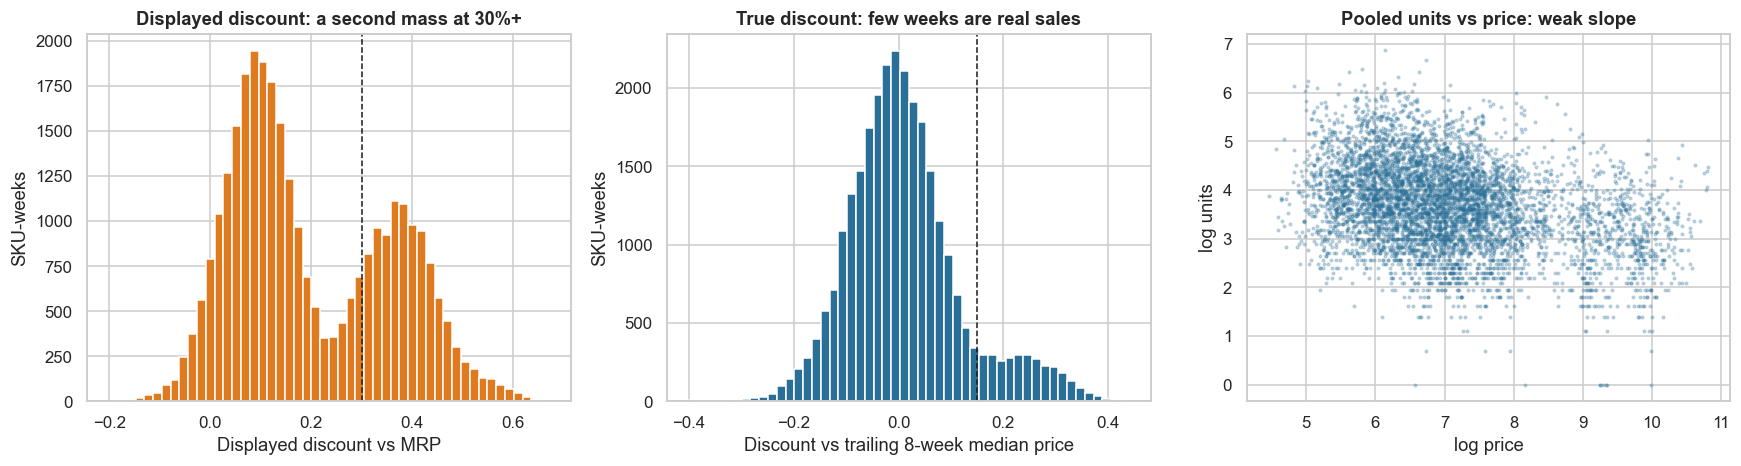

Displayed discount >= 30%: 32.6% of SKU-weeks | true significant discount (>= 15% below trailing median): 10.7% (65.9% in sale weeks, 5.7% otherwise)
Pooled correlation of log price and log units: -0.33 | units per SKU-week: median 39, mean 58


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].hist(d0.disc_shown.clip(-0.2, 0.7), bins=50, color="#e07a1f"); axes[0].axvline(0.30, color="k", ls="--", lw=1); axes[0].set_xlabel("Displayed discount vs MRP"); axes[0].set_ylabel("SKU-weeks"); axes[0].set_title("Displayed discount: a second mass at 30%+")
axes[1].hist(d0.disc_true.dropna().clip(-0.4, 0.5), bins=50, color="#2a6f97"); axes[1].axvline(0.15, color="k", ls="--", lw=1); axes[1].set_xlabel("Discount vs trailing 8-week median price"); axes[1].set_ylabel("SKU-weeks"); axes[1].set_title("True discount: few weeks are real sales")
sm_ = M.sample(6000, random_state=SEED); axes[2].scatter(sm_.lp, sm_.lq, s=3, alpha=0.25, color="#2a6f97"); axes[2].set_xlabel("log price"); axes[2].set_ylabel("log units"); axes[2].set_title("Pooled units vs price: weak slope")
plt.tight_layout(); plt.show()
ev_share = d0.groupby("sale_event").sig_true.mean()
print(f"Displayed discount >= 30%: {d0.sig_shown.mean():.1%} of SKU-weeks | true significant discount (>= 15% below trailing median): {d0.sig_true.mean():.1%} ({ev_share[1]:.1%} in sale weeks, {ev_share[0]:.1%} otherwise)")
print(f"Pooled correlation of log price and log units: {M.lp.corr(M.lq):+.2f} | units per SKU-week: median {d0.units.median():.0f}, mean {d0.units.mean():.0f}")

**Takeaway:** The displayed discount (against MRP) has a second mass at 30% and above, while the discount against the SKU's own trailing median price is concentrated near zero. **32.6%** of SKU-weeks show a badge of 30% or more off, but only **10.7%** are true significant discounts: **65.9%** of SKU-weeks in sale weeks and **5.7%** in other weeks. The pooled correlation of log price and log units is only **−0.33**, much weaker than the hidden elasticities (about −2) would suggest, which is the first sign that price and demand are tangled together. Median units are 39 a SKU-week (mean 58).

## 7. Statistical Analysis (core section)

### 7.1 The ladder of elasticity estimators, checked against the truth

**(a) Why?** A log-log model `log units = ε · log price + …` makes ε the elasticity. The question is which estimate to trust. We climb a ladder:

| Rung | Estimator | What it fixes |
|---|---|---|
| A | Pooled OLS | Nothing: compares expensive and cheap SKUs |
| B | + SKU fixed effects | Compares each SKU with itself |
| C | + sale-week flag and competitor price | Removes sale traffic and price matching |
| D | + week fixed effects | Removes anything common to a week |
| E | **IV (2SLS)**: supplier-cost index as instrument | Removes price changes driven by the demand shock |
| F | **Randomised price test** | Randomisation removes everything |

**(b) Assumptions.** IV needs the cost index to move price (**relevance**, tested by the first-stage F) and to affect demand only through price (**exclusion**, argued, not testable with one instrument). Standard errors are clustered by SKU because weekly shocks are correlated within a SKU. The benchmark "truth" is the average hidden elasticity over the rows each estimator uses.

#### Code

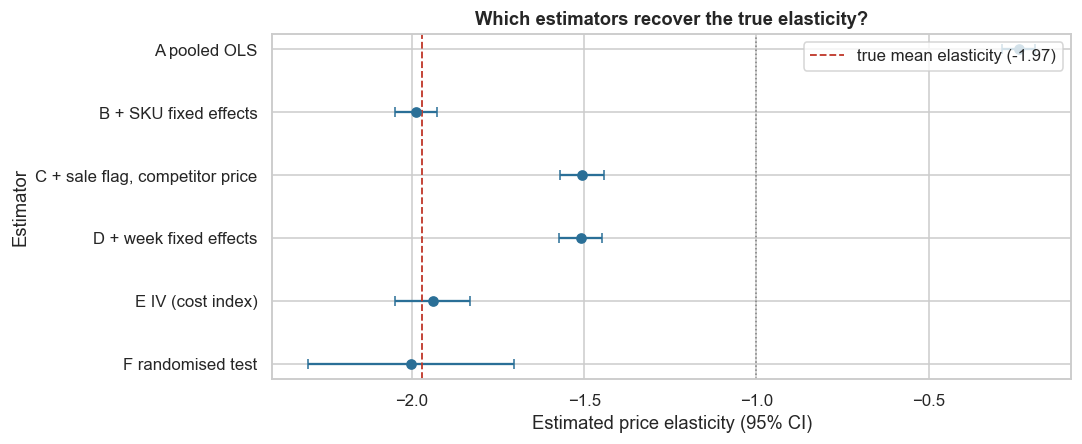

Rows: observational 28,623 | experiment 918


,elasticity,SE (clustered),CI low,CI high,true mean elasticity (same rows),error vs truth
A pooled OLS,-0.2380,0.0240,-0.2860,-0.1910,-1.9710,1.7330
B + SKU fixed effects,-1.9870,0.0310,-2.0480,-1.9260,-1.9710,-0.0160
"C + sale flag, competitor price",-1.5060,0.0330,-1.5700,-1.4410,-1.9710,0.4650
D + week fixed effects,-1.5100,0.0320,-1.5730,-1.4470,-1.9710,0.4610
E IV (cost index),-1.9400,0.0560,-2.0490,-1.8310,-1.9710,0.0310
F randomised test,-2.0020,0.1530,-2.3010,-1.7030,-1.8950,-0.1070


In [7]:
def dm(A, st, cn):
    mean = np.add.reduceat(A, st, axis=0) / cn[:, None]
    return A - np.repeat(mean, cn, axis=0)
def grp(sku):
    st = np.flatnonzero(np.r_[True, sku[1:] != sku[:-1]]); return st, np.diff(np.r_[st, len(sku)])
def fit(y, X, st, cn, Zx=None, within=True):
    """OLS or 2SLS with SKU fixed effects (within transform) and SKU-clustered covariance. Returns b, V, residuals."""
    parts = [y, X] + ([Zx] if Zx is not None else []); A = np.column_stack(parts)
    A = dm(A, st, cn) if within else A; yy, XX = A[:, 0], A[:, 1:1 + X.shape[1]]
    Xh = XX if Zx is None else A[:, 1 + X.shape[1]:] @ np.linalg.lstsq(A[:, 1 + X.shape[1]:], XX, rcond=None)[0]
    Ai = np.linalg.inv(Xh.T @ XX); b = Ai @ (Xh.T @ yy); e = yy - XX @ b
    s = np.add.reduceat(Xh * e[:, None], st, axis=0); G = len(st); V = Ai @ (s.T @ s) @ Ai.T * G / (G - 1)
    return b, V, e
M = M.sort_values(["sku_id", "week"]).reset_index(drop=True); st, cn = grp(M.sku_id.values)
y = M.lq.values; lp = M.lp.values; lc = M.lc.values; lz = M.lz.values; ev = M.sale_event.values.astype(float)
WK = pd.get_dummies(M.week, drop_first=True, dtype=float).values
truth_obs = M._eps.mean()
res = {}
b, V, _ = fit(y, np.column_stack([lp, np.ones(len(y))]), st, cn, within=False); res["A pooled OLS"] = (b[0], np.sqrt(V[0, 0]))
b, V, _ = fit(y, lp[:, None], st, cn); res["B + SKU fixed effects"] = (b[0], np.sqrt(V[0, 0]))
b, V, eC = fit(y, np.column_stack([lp, lc, ev]), st, cn); res["C + sale flag, competitor price"] = (b[0], np.sqrt(V[0, 0]))
b, V, _ = fit(y, np.column_stack([lp, lc, WK]), st, cn); res["D + week fixed effects"] = (b[0], np.sqrt(V[0, 0]))
bI, VI, eI = fit(y, np.column_stack([lp, lc, ev]), st, cn, Zx=np.column_stack([lc, ev, lz])); res["E IV (cost index)"] = (bI[0], np.sqrt(VI[0, 0]))
Ex = d0[(d0.exp_arm != "") & (d0.in_stock == 1) & (d0.units > 0)].sort_values(["sku_id", "week"]).reset_index(drop=True)
Ex["a"] = Ex.exp_arm.map({"cut10": np.log(0.9), "control": 0.0, "raise10": np.log(1.1)}); stx, cnx = grp(Ex.sku_id.values)
bF, VF, eF = fit(Ex.lq.values, Ex.a.values[:, None], stx, cnx); res["F randomised test"] = (bF[0], np.sqrt(VF[0, 0]))
truth_exp = Ex.merge(skus[["sku_id", "_true_elasticity"]], on="sku_id")._true_elasticity.mean()
lad = pd.DataFrame(res, index=["elasticity", "SE (clustered)"]).T; lad["CI low"] = lad.elasticity - 1.96 * lad["SE (clustered)"]; lad["CI high"] = lad.elasticity + 1.96 * lad["SE (clustered)"]
lad["true mean elasticity (same rows)"] = [truth_obs] * 5 + [truth_exp]; lad["error vs truth"] = lad.elasticity - lad["true mean elasticity (same rows)"]
fig, ax = plt.subplots(figsize=(10, 4.2)); yy_ = np.arange(len(lad))[::-1]
ax.errorbar(lad.elasticity, yy_, xerr=1.96 * lad["SE (clustered)"], fmt="o", color="#2a6f97", capsize=3); ax.axvline(truth_obs, color="#c0392b", ls="--", lw=1.2, label=f"true mean elasticity ({truth_obs:.2f})"); ax.axvline(-1, color="grey", ls=":", lw=1)
ax.set_yticks(yy_); ax.set_yticklabels(lad.index); ax.set_xlabel("Estimated price elasticity (95% CI)"); ax.set_ylabel("Estimator"); ax.set_title("Which estimators recover the true elasticity?"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
print(f"Rows: observational {len(M):,} | experiment {len(Ex):,}")
lad.round(3)

**Takeaway:** The ladder shows the identification problem clearly. **Pooled OLS gives −0.24** (CI −0.29 to −0.19) against a true mean of **−1.97**, an error of +1.73: it compares expensive and cheap SKUs, not price changes. **SKU fixed effects give −1.99** (error −0.02), but this is close by luck: adding the sale flag and competitor price (rung C) moves the estimate to **−1.51** (CI −1.57 to −1.44) and week effects (rung D) leave it at −1.51, both 0.46 too close to zero. The remaining bias comes from sellers raising price after strong weeks, which fixed effects and these controls do not remove. We did not isolate the separate biases; we only see that the estimate depends on which controls are added. **IV with the supplier-cost index gives −1.94** (CI −2.05 to −1.83, error +0.03) and the **randomised test gives −2.00** (CI −2.30 to −1.70; its truth is −1.90 on the experiment SKUs). The experiment's CI is about three times wider than IV's because it has only 918 rows.

### 7.1b Diagnostics: first stage, bias test, heteroskedasticity, serial correlation

**(a) Why?** We check the pieces the IV argument rests on.
- **Relevance:** first-stage F for the cost index (F > 10 is the usual rule of thumb).
- **H1 (Hausman-type):** is IV different from fixed-effects OLS? We bootstrap whole SKUs (200 resamples) to get the standard error of the difference.
- **Heteroskedasticity:** Breusch–Pagan on the pooled model, which is why clustered errors are used.
- **Serial correlation:** correlation of a SKU's residual with its previous week's, and a sanity check that the cost index is uncorrelated with the previous week's residual.

#### Code

In [8]:
bF1, VF1, _ = fit(lp, np.column_stack([lc, ev, lz]), st, cn); F1 = (bF1[2] ** 2) / VF1[2, 2]
bp = het_breuschpagan(sm.OLS(y, sm.add_constant(lp)).fit().resid, sm.add_constant(lp))
prev = M.sku_id.values[1:] == M.sku_id.values[:-1]; contig = prev & (np.diff(M.week.values) == 1)
ac = np.corrcoef(eI[1:][contig], eI[:-1][contig])[0, 1]; zc = np.corrcoef(M.lz.values[1:][contig] - M.groupby("sku_id").lz.transform("mean").values[1:][contig], eI[:-1][contig])[0, 1]
boot = []; t0 = time.time(); XC = np.column_stack([lp, lc, ev]); ZC = np.column_stack([lc, ev, lz])
for _ in range(200):
    sel = RNG.integers(0, len(st), len(st)); idx = np.concatenate([np.arange(st[i], st[i] + cn[i]) for i in sel]); cn2 = cn[sel]; st2 = np.r_[0, np.cumsum(cn2)[:-1]]
    bc, _, _ = fit(y[idx], XC[idx], st2, cn2); bi, _, _ = fit(y[idx], XC[idx], st2, cn2, Zx=ZC[idx]); boot.append((bc[0], bi[0]))
boot = np.array(boot); diff = res["E IV (cost index)"][0] - res["C + sale flag, competitor price"][0]; se_d = (boot[:, 1] - boot[:, 0]).std(ddof=1); zH = diff / se_d
print(f"First-stage F (cost index -> log price): {F1:.0f} | coefficient {bF1[2]:.2f}")
print(f"Hausman-type test, IV minus FE-OLS (rung C): difference {diff:+.3f}, bootstrap SE {se_d:.3f}, z = {zH:.1f}, p = {2 * stats.norm.sf(abs(zH)):.2g}")
print(f"Bootstrap 95% CI of the IV elasticity: ({np.percentile(boot[:, 1], 2.5):.2f}, {np.percentile(boot[:, 1], 97.5):.2f}) | analytic: ({lad.loc['E IV (cost index)', 'CI low']:.2f}, {lad.loc['E IV (cost index)', 'CI high']:.2f}) | {time.time() - t0:.0f}s")
print(f"Breusch-Pagan on pooled model: LM = {bp[0]:.1f}, p = {bp[1]:.2g} | week-to-week residual autocorrelation (IV residuals): {ac:+.2f} | corr(cost shock, previous week's residual): {zc:+.3f}")
print(f"H1 against the experiment: naive pooled {lad.iloc[0, 0]:.2f} vs experiment {lad.iloc[5, 0]:.2f}; z = {(lad.iloc[0, 0] - lad.iloc[5, 0]) / np.hypot(lad.iloc[0, 1], lad.iloc[5, 1]):.1f}")

First-stage F (cost index -> log price): 5658 | coefficient 0.82
Hausman-type test, IV minus FE-OLS (rung C): difference -0.434, bootstrap SE 0.047, z = -9.2, p = 2.5e-20
Bootstrap 95% CI of the IV elasticity: (-2.06, -1.84) | analytic: (-2.05, -1.83) | 5s
Breusch-Pagan on pooled model: LM = 0.5, p = 0.5 | week-to-week residual autocorrelation (IV residuals): +0.20 | corr(cost shock, previous week's residual): +0.003
H1 against the experiment: naive pooled -0.24 vs experiment -2.00; z = 11.4


**Observation:** The cost index is a very strong instrument (first-stage F = **5,658**; a 1% cost shock moves price by 0.82%) and is uncorrelated with the previous week's residual (+0.003), as the exclusion argument needs; this check cannot prove exclusion with a single instrument. **H1 is rejected two ways:** IV differs from fixed-effects OLS by −0.43 (bootstrap SE 0.047, z = −9.2, p = 2.5e-20), and the naive pooled estimate differs from the experiment by z = 11.4. The bootstrap CI for IV (−2.06 to −1.84) matches the analytic one (−2.05 to −1.83). Residuals are correlated across weeks (+0.20), which supports clustering by SKU. Breusch–Pagan does not detect heteroskedasticity in the pooled model (p = 0.5).

### 7.2 Elasticity by category (H2) with Holm correction

**(a) Why?** Discount policy is set by category, so we need an elasticity and a CI for each. H0 for each is **ε = −1** (a price change leaves revenue unchanged; below −1 a cut raises revenue). Eight tests, so **Holm** correction. We also show the first-stage F in each category and the truth.

#### Code

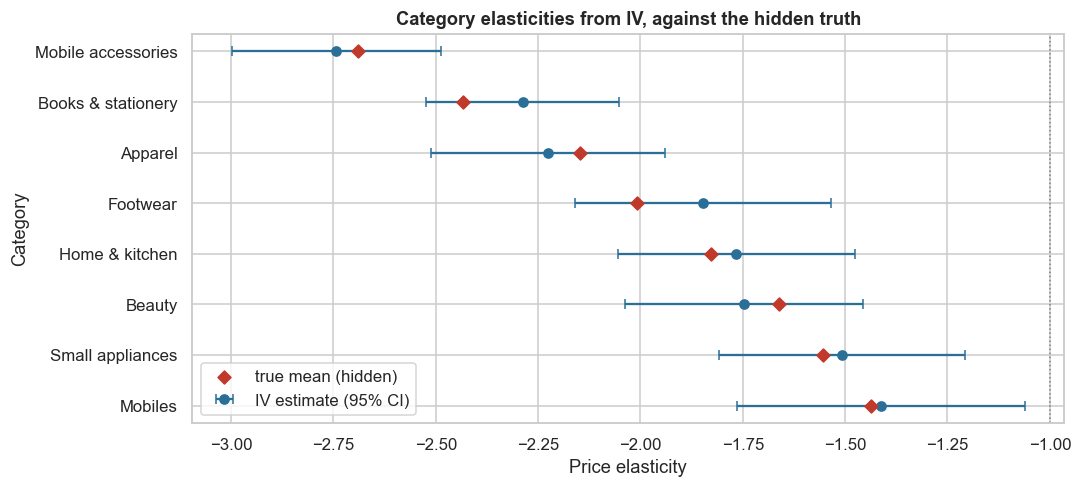

CI covers truth in 8 of 8 categories | first-stage F range 567 to 847


,IV elasticity,SE,CI low,CI high,true mean,p (H0: ε = -1),first-stage F,rows,p_holm,covers truth,elastic (CI high < -1)
category,,,,,,,,,,,
Mobile accessories,-2.7420,0.1300,-2.9980,-2.4870,-2.6910,0.0000,843.0170,3576,0.0000,True,True
Books & stationery,-2.2870,0.1200,-2.5230,-2.0510,-2.4330,0.0000,846.5140,3592,0.0000,True,True
Apparel,-2.2260,0.1460,-2.5110,-1.9410,-2.1460,0.0000,646.7500,3579,0.0000,True,True
Footwear,-1.8480,0.1600,-2.1600,-1.5350,-2.0090,0.0000,630.9010,3593,0.0000,True,True
Home & kitchen,-1.7650,0.1480,-2.0550,-1.4760,-1.8280,0.0000,812.7320,3555,0.0000,True,True
Beauty,-1.7460,0.1490,-2.0380,-1.4550,-1.6630,0.0000,574.5080,3609,0.0000,True,True
Small appliances,-1.5070,0.1530,-1.8070,-1.2070,-1.5550,0.0010,567.3770,3554,0.0030,True,True
Mobiles,-1.4120,0.1790,-1.7630,-1.0610,-1.4380,0.0240,831.0160,3565,0.0240,True,True


In [9]:
rows = []
for c in sorted(M.category.unique()):
    mc = (M.category == c).values; yc, X_, Z_ = y[mc], XC[mc], ZC[mc]; stc, cnc = grp(M.sku_id.values[mc])
    b, V, _ = fit(yc, X_, stc, cnc, Zx=Z_); se = np.sqrt(V[0, 0]); b1, V1, _ = fit(lp[mc], ZC[mc], stc, cnc); f1 = b1[2] ** 2 / V1[2, 2]; G = len(stc)
    rows.append((c, b[0], se, b[0] - 1.96 * se, b[0] + 1.96 * se, M.loc[mc, "_eps"].mean(), 2 * stats.t.sf(abs((b[0] + 1) / se), G - 1), f1, int(mc.sum())))
cat = pd.DataFrame(rows, columns=["category", "IV elasticity", "SE", "CI low", "CI high", "true mean", "p (H0: ε = -1)", "first-stage F", "rows"]).set_index("category")
cat["p_holm"] = multipletests(cat["p (H0: ε = -1)"], method="holm")[1]; cat["covers truth"] = (cat["CI low"] <= cat["true mean"]) & (cat["true mean"] <= cat["CI high"]); cat["elastic (CI high < -1)"] = cat["CI high"] < -1
cat = cat.sort_values("IV elasticity")
fig, ax = plt.subplots(figsize=(10, 4.6)); yy_ = np.arange(len(cat))[::-1]
ax.errorbar(cat["IV elasticity"], yy_, xerr=[cat["IV elasticity"] - cat["CI low"], cat["CI high"] - cat["IV elasticity"]], fmt="o", color="#2a6f97", capsize=3, label="IV estimate (95% CI)"); ax.scatter(cat["true mean"], yy_, marker="D", color="#c0392b", zorder=3, label="true mean (hidden)"); ax.axvline(-1, color="grey", ls=":", lw=1)
ax.set_yticks(yy_); ax.set_yticklabels(cat.index); ax.set_xlabel("Price elasticity"); ax.set_ylabel("Category"); ax.set_title("Category elasticities from IV, against the hidden truth"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
print(f"CI covers truth in {int(cat['covers truth'].sum())} of {len(cat)} categories | first-stage F range {cat['first-stage F'].min():.0f} to {cat['first-stage F'].max():.0f}")
cat.round(3)

**Takeaway:** All eight categories are **price-elastic**. IV elasticities run from **−2.74 (mobile accessories)** and −2.29 (books and stationery) to **−1.41 (mobiles)**. H0: ε = −1 is rejected in every category after Holm correction, though mobiles only just (p_holm = 0.024; CI −1.76 to −1.06, whose upper end is close to −1) and small appliances (p_holm = 0.003; CI −1.81 to −1.21) are the weakest. The ordering of the estimates matches the hidden category means and all eight **CIs cover the truth**. First-stage F ranges from 567 to 847, so no category suffers from a weak instrument. Category CIs are 0.5 to 0.7 wide, so two neighbouring categories (for example footwear at −1.85 and home and kitchen at −1.77) are not distinguishable.

### 7.3 The randomised price test: analysis, balance and power

**(a) Why?** Randomisation is the cleanest evidence, but only 120 SKUs for 8 weeks. We check **balance** (are arms alike in prior sales, one-way ANOVA), estimate the elasticity with SKU fixed effects, estimate the **price-cut and price-rise** slopes separately (asymmetry test), and compute the **sample size** needed for a given CI half-width.

#### Code

In [10]:
pre = d0[(d0.week.between(35, 42))].groupby("sku_id").lq.mean(); Ex["pre_lq"] = Ex.sku_id.map(pre)
bal = [Ex.loc[Ex.exp_arm == a_, "pre_lq"].values for a_ in ("cut10", "control", "raise10")]; fa = stats.f_oneway(*bal)
print("Arm sizes (SKU-weeks):", Ex.exp_arm.value_counts().to_dict(), f"| balance on prior-8-week log units: ANOVA F = {fa.statistic:.2f}, p = {fa.pvalue:.2f}")
Xs = np.column_stack([np.minimum(Ex.a.values, 0), np.maximum(Ex.a.values, 0)]); bS, VS, _ = fit(Ex.lq.values, Xs, stx, cnx)
zA = (bS[0] - bS[1]) / np.sqrt(VS[0, 0] + VS[1, 1] - 2 * VS[0, 1])
print(f"Pooled experiment elasticity {bF[0]:.2f} (SE {np.sqrt(VF[0, 0]):.2f}) | price-cut slope {bS[0]:.2f} (SE {np.sqrt(VS[0, 0]):.2f}) | price-rise slope {bS[1]:.2f} (SE {np.sqrt(VS[1, 1]):.2f}) | asymmetry test z = {zA:.2f}, p = {2 * stats.norm.sf(abs(zA)):.2f}")
means = Ex.groupby("exp_arm").agg(SKU_weeks=("lq", "size"), mean_units=("units", "mean"), mean_log_units=("lq", "mean")).loc[["cut10", "control", "raise10"]]
sd_e = eF.std(); sd_a = dm(Ex.a.values[:, None], stx, cnx).std(); se_now = np.sqrt(VF[0, 0])
need = pd.DataFrame({"CI half-width target": [0.5, 0.3, 0.2, 0.1]}); need["SKU-weeks needed"] = np.ceil((1.96 * sd_e / (sd_a * need["CI half-width target"])) ** 2).astype(int); need["≈ SKUs for 8 weeks"] = np.ceil(need["SKU-weeks needed"] / 8).astype(int)
print(f"Residual sd {sd_e:.2f}, sd of price variation {sd_a:.3f} | current half-width {1.96 * se_now:.2f} | minimum detectable elasticity (80% power, 5% level) {2.8 * se_now:.2f}")
print(means.round(2).to_string()); need

Arm sizes (SKU-weeks): {'control': 328, 'cut10': 314, 'raise10': 276} | balance on prior-8-week log units: ANOVA F = 0.74, p = 0.48
Pooled experiment elasticity -2.00 (SE 0.15) | price-cut slope -2.17 (SE 0.27) | price-rise slope -1.80 (SE 0.32) | asymmetry test z = -0.74, p = 0.46
Residual sd 0.31, sd of price variation 0.076 | current half-width 0.30 | minimum detectable elasticity (80% power, 5% level) 0.43
         SKU_weeks  mean_units  mean_log_units
exp_arm                                       
cut10          314     61.5500          3.8000
control        328     46.7800          3.5200
raise10        276     42.0100          3.4000


,CI half-width target,SKU-weeks needed,≈ SKUs for 8 weeks
0,0.5000,259,33
1,0.3000,719,90
2,0.2000,1617,203
3,0.1000,6466,809


**Observation:** The three arms are balanced on prior sales (ANOVA p = 0.48). The experiment gives an elasticity of **−2.00** (SE 0.15; CI half-width 0.30). Price cuts give a slope of −2.17 (SE 0.27) and price rises −1.80 (SE 0.32); the asymmetry test finds no difference (z = −0.74, p = 0.46), so we cannot say that rises and cuts act differently, with only about 300 SKU-weeks per arm. Mean units are 61.6 under a 10% cut, 46.8 in control and 42.0 under a 10% rise. **Power:** the minimum detectable elasticity is 0.43. To narrow the CI half-width to 0.3 we would need about 719 SKU-weeks (about 90 SKUs for 8 weeks); to 0.2, 1,617 (about 203 SKUs); to 0.1, 6,466 (about 809 SKUs). A category-level experiment (about 75 SKUs here) cannot reach the precision of the IV estimates, so IV and experiments serve different jobs: IV for breadth, an experiment for validation.

### 7.4 Promotion event study: gross lift, the dip and the net effect (H3)

**(a) Why?** A promotion's sale-week lift overstates its value if demand is pulled forward. We flag a **promotion** when the price is at least 15% below the SKU's trailing 8-week median, then regress log units on the promotion flag and its first two lags, with SKU and week fixed effects and the competitor price. The **net effect over three weeks** is the average of the three multipliers minus 1; its CI comes from a cluster bootstrap (200 resamples of SKUs). Because the flag is built from noisy observed prices, we also report how often it matches the hidden true promotion.

#### Code

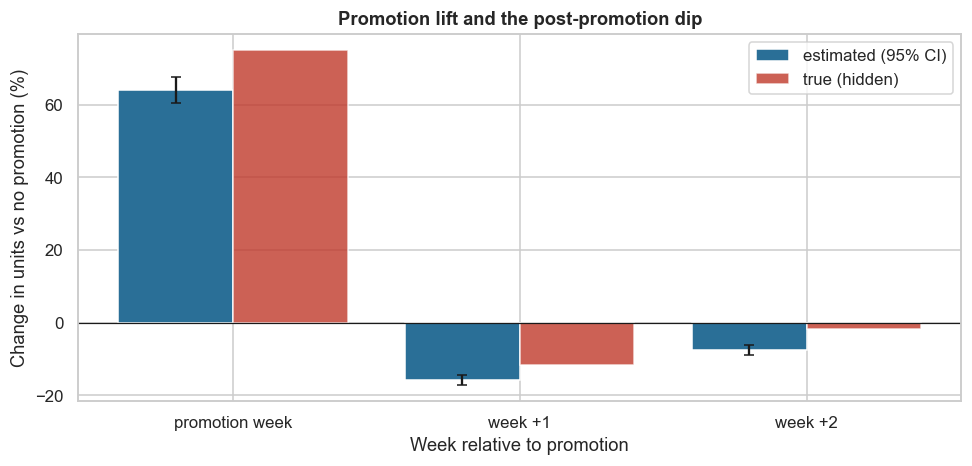

Promotions flagged: 2,427 of 24,369 SKU-weeks (10.0%); flag precision vs hidden truth 92.6%, recall 87.0%
Net effect over 3 weeks (average multiplier - 1): +13.6% (95% CI +12.3% to +14.9%) | true net +24.2% | dip in weeks +1 and +2 as a share of the sale-week lift: 36%
Dip scaling used in section 9 (log lift in week +1 and +2 as a multiple of the sale-week log lift): -0.35 and -0.16


,estimated lift,CI low,CI high,true lift (hidden)
promotion week,0.6410,0.6060,0.6770,0.7500
week +1,-0.1570,-0.1710,-0.1440,-0.1160
week +2,-0.0760,-0.0900,-0.0600,-0.0190


In [11]:
d0["promo"] = d0.sig_true
for k in (1, 2):
    ok = (d0.sku_id == d0.sku_id.shift(k)) & (d0.week - d0.week.shift(k) == k); d0[f"promo_l{k}"] = np.where(ok, d0.promo.shift(k), np.nan)
    ok2 = (d0.sku_id == d0.sku_id.shift(-k)) & (d0.week.shift(-k) - d0.week == k); d0[f"mu_f{k}"] = np.where(ok2, d0._mu.shift(-k), np.nan); d0[f"mucf_f{k}"] = np.where(ok2, d0._mu_cf.shift(-k), np.nan)
ES = d0[d0.obs & (d0.in_stock == 1) & (d0.units > 0)].dropna(subset=["promo", "promo_l1", "promo_l2"]).sort_values(["sku_id", "week"]).reset_index(drop=True); ste, cne = grp(ES.sku_id.values)
Wes = pd.get_dummies(ES.week, drop_first=True, dtype=float).values; Xe = np.column_stack([ES.promo, ES.promo_l1, ES.promo_l2, ES.lc, Wes]); ye = ES.lq.values
bE, VE, _ = fit(ye, Xe, ste, cne); sE = np.sqrt(np.diag(VE)[:3]); gross = np.exp(bE[:3]) - 1; lo = np.exp(bE[:3] - 1.96 * sE) - 1; hi = np.exp(bE[:3] + 1.96 * sE) - 1
netm = lambda b3: np.exp(b3).mean() - 1; net = netm(bE[:3]); nb = []
for _ in range(200):
    sel = RNG.integers(0, len(ste), len(ste)); idx = np.concatenate([np.arange(ste[i], ste[i] + cne[i]) for i in sel]); cn2 = cne[sel]; st2 = np.r_[0, np.cumsum(cn2)[:-1]]
    bb, _, _ = fit(ye[idx], Xe[idx], st2, cn2); nb.append(netm(bb[:3]))
net_ci = (np.percentile(nb, 2.5), np.percentile(nb, 97.5)); R1, R2 = bE[1] / bE[0], bE[2] / bE[0]
P = d0[(d0.promo == 1) & d0.obs]; Pm = P.dropna(subset=["mu_f1", "mu_f2"])
true_ = [P._mu.sum() / P._mu_cf.sum() - 1, Pm.mu_f1.sum() / Pm.mucf_f1.sum() - 1, Pm.mu_f2.sum() / Pm.mucf_f2.sum() - 1]; true_net = (Pm._mu.sum() + Pm.mu_f1.sum() + Pm.mu_f2.sum()) / (Pm._mu_cf.sum() + Pm.mucf_f1.sum() + Pm.mucf_f2.sum()) - 1
Dd = d0[d0.obs & d0.promo.notna()]; prec = (Dd[Dd.promo == 1]._promo_m < -0.10).mean(); rec = (Dd[Dd._promo_m < -0.10].promo == 1).mean()
tab = pd.DataFrame({"estimated lift": gross, "CI low": lo, "CI high": hi, "true lift (hidden)": true_}, index=["promotion week", "week +1", "week +2"])
fig, ax = plt.subplots(figsize=(9, 4.4)); xx = np.arange(3)
ax.bar(xx - 0.2, gross * 100, 0.4, yerr=[(gross - lo) * 100, (hi - gross) * 100], color="#2a6f97", capsize=3, label="estimated (95% CI)"); ax.bar(xx + 0.2, np.array(true_) * 100, 0.4, color="#c0392b", alpha=0.8, label="true (hidden)"); ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels(tab.index); ax.set_xlabel("Week relative to promotion"); ax.set_ylabel("Change in units vs no promotion (%)"); ax.set_title("Promotion lift and the post-promotion dip"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Promotions flagged: {int(ES.promo.sum()):,} of {len(ES):,} SKU-weeks ({ES.promo.mean():.1%}); flag precision vs hidden truth {prec:.1%}, recall {rec:.1%}")
print(f"Net effect over 3 weeks (average multiplier - 1): {net:+.1%} (95% CI {net_ci[0]:+.1%} to {net_ci[1]:+.1%}) | true net {true_net:+.1%} | dip in weeks +1 and +2 as a share of the sale-week lift: {-(gross[1] + gross[2]) / gross[0]:.0%}")
print(f"Dip scaling used in section 9 (log lift in week +1 and +2 as a multiple of the sale-week log lift): {R1:.2f} and {R2:.2f}")
tab.round(3)

**Takeaway:** A promotion lifts units by an estimated **+64.1%** in the sale week (CI +60.6% to +67.7%) and then loses **15.7%** and **7.6%** in the next two weeks; the dip is about **36% of the sale-week lift** (these are percent changes in units). The average three-week net effect is **+13.6%** (cluster-bootstrap CI +12.3% to +14.9%), so **H3 (zero net effect) is rejected** and promotions raise units even after the dip. But the estimate is not exact: the truth in the simulation is **+75.0%** in the promotion week, −11.6% and −1.9% in the next weeks, and a net **+24.2%**, so the event study **understates the lift and overstates the dip**, and its CIs do not cover the true values. The promotion flag is built from noisy observed prices (precision 92.6%, recall 87.0% against the hidden truth), which blurs promotion and non-promotion weeks. Treat the event-study dip as a conservative estimate. The estimated dip pattern (log dip in week +1 and +2 equals −0.35 and −0.16 times the sale-week log lift) is what section 9 uses.

### 7.5 Is the badge honest? Displayed vs true discount (H4)

**(a) Why?** The paper's core question is whether a sale discount is significant. A badge of "30% off MRP" compares the price with the list price, which can be inflated. We compare the **badge** (≥ 30% off MRP) with the **true significant discount** (≥ 15% below the trailing 8-week median). Agreement is measured with **Cohen's kappa** (bootstrap CI over SKUs) and **McNemar** on the disagreements; the hidden MRP-inflation flag shows where the false badges come from.

#### Code

In [12]:
Q = d0.dropna(subset=["sig_true"]).merge(skus[["sku_id", "_mrp_inflated"]], on="sku_id"); a_, b_ = Q.sig_shown.values, Q.sig_true.values.astype(int)
ct = pd.crosstab(Q.sig_shown.map({0: "badge: no", 1: "badge: yes"}), Q.sig_true.map({0.0: "true sale: no", 1.0: "true sale: yes"}))
kap = cohen_kappa_score(a_, b_); sk_ids = Q.sku_id.values; ust = np.unique(sk_ids); idxs = {u_: np.flatnonzero(sk_ids == u_) for u_ in ust}; kb = []
for _ in range(200):
    ii = np.concatenate([idxs[u_] for u_ in RNG.choice(ust, len(ust))]); kb.append(cohen_kappa_score(a_[ii], b_[ii]))
n01 = int(((a_ == 1) & (b_ == 0)).sum()); n10 = int(((a_ == 0) & (b_ == 1)).sum()); mc = mcnemar([[int(((a_ == 1) & (b_ == 1)).sum()), n01], [n10, int(((a_ == 0) & (b_ == 0)).sum())]], exact=False, correction=True)
prec_b = ((a_ == 1) & (b_ == 1)).sum() / (a_ == 1).sum(); rec_b = ((a_ == 1) & (b_ == 1)).sum() / (b_ == 1).sum()
fake = Q[(Q.sig_shown == 1) & (Q.sig_true == 0)]; infl_share = fake._mrp_inflated.mean(); infl_skus = skus._mrp_inflated.mean()
print(ct.to_string())
print(f"\nBadge precision (badge weeks that are real sales): {prec_b:.1%} | recall (real sales that show the badge): {rec_b:.1%}")
print(f"Cohen's kappa {kap:.3f} (bootstrap 95% CI {np.percentile(kb, 2.5):.3f} to {np.percentile(kb, 97.5):.3f}) | McNemar: badge-only {n01:,} vs true-only {n10:,}, p = {mc.pvalue:.2g}")
print(f"Share of false-badge weeks on inflated-MRP SKUs: {infl_share:.1%} (inflated SKUs are {infl_skus:.1%} of the catalogue)")
ct

sig_true    true sale: no  true sale: yes
sig_shown                                
badge: no           18186             806
badge: yes           7103            2217

Badge precision (badge weeks that are real sales): 23.8% | recall (real sales that show the badge): 73.3%
Cohen's kappa 0.236 (bootstrap 95% CI 0.209 to 0.268) | McNemar: badge-only 7,103 vs true-only 806, p = 0
Share of false-badge weeks on inflated-MRP SKUs: 100.0% (inflated SKUs are 32.2% of the catalogue)


sig_true,true sale: no,true sale: yes
sig_shown,,
badge: no,18186,806
badge: yes,7103,2217


**Observation:** The badge disagrees with the true test. Of 9,320 SKU-weeks showing 30% or more off MRP, only **2,217 (23.8%)** are real sales (precision); the badge catches **73.3%** of real sales (recall). Cohen's kappa is **0.236** (bootstrap CI 0.209 to 0.268), only fair agreement. McNemar on the disagreements: 7,103 badge-only weeks against 806 true-only weeks (the p-value prints as 0, below floating-point resolution). **H4 is rejected**: the badge is not an honest test. Every one of the false-badge weeks (100.0%) is on an inflated-MRP SKU, although such SKUs are 32.2% of the catalogue. A 30% badge says more about the MRP than about the price move, so a reference price based on the SKU's own price history, as used here, is the sensible check. This mirrors the paper's concern, but we do not know how the paper defined significance.

## 8. ML Section — can a classifier call a discount "significant"? (H5)

This is the paper's task. We predict `sig_true` (≥ 15% below the trailing median) for each SKU-week with an **SVM (RBF)**, **logistic regression** and **gradient boosting**, using a **70/30 split by SKU** (no SKU in both sets). Two feature sets:
- **A (with calendar):** product features, MRP, MRP relative to the trailing price, and the sale-event flag.
- **B (product and price only):** the paper's setting, without the sale-event flag.

Because only a small share of SKU-weeks are significant discounts, **accuracy alone is misleading**: always predicting "not significant" already scores high. We report accuracy against that **majority baseline**, balanced accuracy, F1 and PR-AUC (average precision; its baseline is the prevalence). No tuning: default settings, SVM trained on 6,000 SKU-weeks.

#### Code

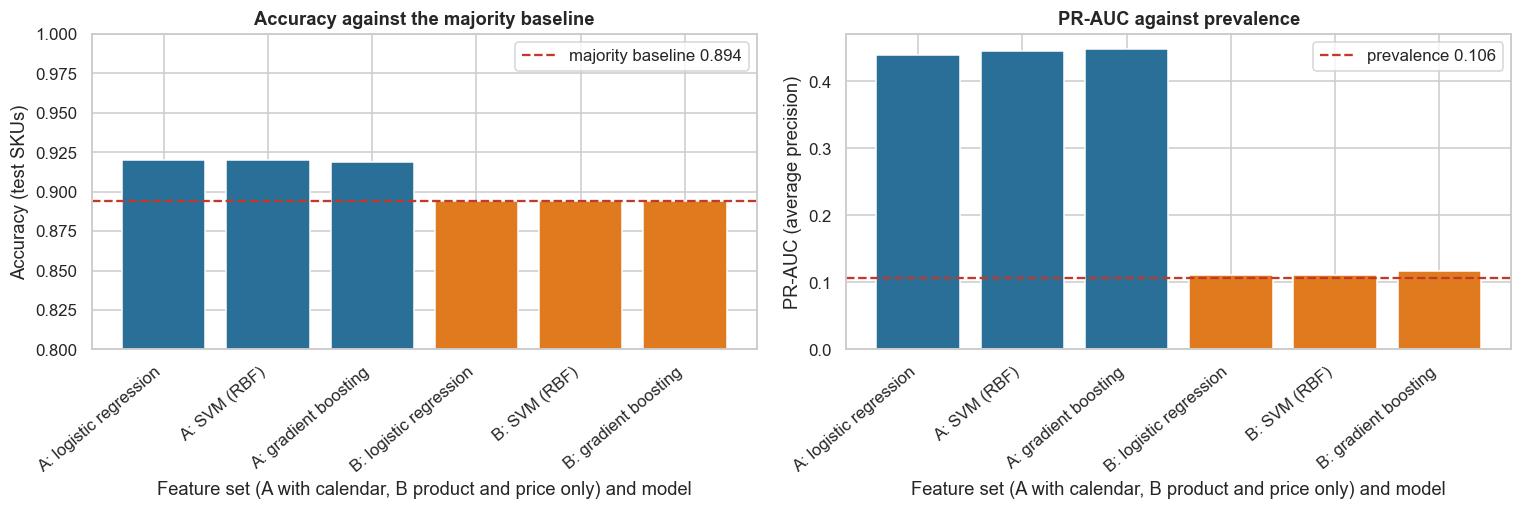

Train 19,824 / test 8,488 SKU-weeks | test prevalence of significant discounts 10.6% | majority-baseline accuracy 0.894
Best by PR-AUC: ('A with calendar', 'gradient boosting') | McNemar vs majority baseline: model-only correct 445, majority-only correct 231, p = 2.6e-16


accuracy  balanced accuracy     F1  PR-AUC
features                 model                                                          
A with calendar          logistic regression    0.9199             0.7388 0.5745  0.4396
                         SVM (RBF)              0.9199             0.7388 0.5745  0.4449
                         gradient boosting      0.9189             0.7314 0.5640  0.4485
B product and price only logistic regression    0.8937             0.5000 0.0000  0.1109
                         SVM (RBF)              0.8937             0.5000 0.0000  0.1109
                         gradient boosting      0.8937             0.5000 0.0000  0.1167

In [13]:
Z = d0.dropna(subset=["sig_true"]).copy(); Z["log_rev"] = np.log(Z.review_count); Z["log_mrp"] = np.log(Z.mrp_inr); Z["mrp_over_ref"] = Z.mrp_inr / Z.ref_price
base_cols = ["brand_tier", "rating", "log_rev", "log_mrp", "mrp_over_ref"]; catd = pd.get_dummies(Z.category, dtype=float)
FA = pd.concat([Z[base_cols + ["sale_event"]].astype(float), catd], axis=1); FB = pd.concat([Z[base_cols].astype(float), catd], axis=1); yz = Z.sig_true.values.astype(int)
ids = Z.sku_id.unique(); test_ids = RNG.choice(ids, int(0.3 * len(ids)), replace=False); te = Z.sku_id.isin(test_ids).values; tr = ~te
prev_te = yz[te].mean(); maj_acc = 1 - prev_te; rows = []; PRED = {}; SCORE = {}; yte = yz[te]
for fs_name, F in (("A with calendar", FA), ("B product and price only", FB)):
    sc = StandardScaler().fit(F[tr]); Xtr, Xte = sc.transform(F[tr]), sc.transform(F[te]); ytr = yz[tr]
    sub = RNG.choice(len(ytr), 6000, replace=False)
    models = {"logistic regression": (LogisticRegression(max_iter=1000), Xtr, ytr), "SVM (RBF)": (SVC(kernel="rbf", gamma="scale", C=1.0), Xtr[sub], ytr[sub]), "gradient boosting": (HistGradientBoostingClassifier(random_state=SEED), Xtr, ytr)}
    for mn, (mdl, Xf, yf) in models.items():
        mdl.fit(Xf, yf); pr = mdl.predict(Xte); s_ = mdl.predict_proba(Xte)[:, 1] if mn == "gradient boosting" else mdl.decision_function(Xte); PRED[(fs_name, mn)] = pr; SCORE[(fs_name, mn)] = s_
        rows.append((fs_name, mn, accuracy_score(yte, pr), balanced_accuracy_score(yte, pr), f1_score(yte, pr), average_precision_score(yte, s_)))
mlr = pd.DataFrame(rows, columns=["features", "model", "accuracy", "balanced accuracy", "F1", "PR-AUC"]).set_index(["features", "model"])
best_key = max(PRED, key=lambda k: average_precision_score(yte, SCORE[k])); pb = PRED[best_key]; cm_ = pb == yte; cj_ = yte == 0
mcb = mcnemar([[int((cm_ & cj_).sum()), int((cm_ & ~cj_).sum())], [int((~cm_ & cj_).sum()), int((~cm_ & ~cj_).sum())]], exact=False, correction=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); lab = [f"{k[0][0]}: {k[1]}" for k in mlr.index]; cols = ["#2a6f97"] * 3 + ["#e07a1f"] * 3
axes[0].bar(range(len(lab)), mlr.accuracy.values, color=cols); axes[0].axhline(maj_acc, color="#c0392b", ls="--", label=f"majority baseline {maj_acc:.3f}"); axes[0].set_ylim(0.8, 1.0); axes[0].set_xticks(range(len(lab))); axes[0].set_xticklabels(lab, rotation=40, ha="right"); axes[0].set_xlabel("Feature set (A with calendar, B product and price only) and model"); axes[0].set_ylabel("Accuracy (test SKUs)"); axes[0].set_title("Accuracy against the majority baseline"); axes[0].legend()
axes[1].bar(range(len(lab)), mlr["PR-AUC"].values, color=cols); axes[1].axhline(prev_te, color="#c0392b", ls="--", label=f"prevalence {prev_te:.3f}"); axes[1].set_xticks(range(len(lab))); axes[1].set_xticklabels(lab, rotation=40, ha="right"); axes[1].set_xlabel("Feature set (A with calendar, B product and price only) and model"); axes[1].set_ylabel("PR-AUC (average precision)"); axes[1].set_title("PR-AUC against prevalence"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Train {tr.sum():,} / test {te.sum():,} SKU-weeks | test prevalence of significant discounts {prev_te:.1%} | majority-baseline accuracy {maj_acc:.3f}")
print(f"Best by PR-AUC: {best_key} | McNemar vs majority baseline: model-only correct {int((cm_ & ~cj_).sum()):,}, majority-only correct {int((~cm_ & cj_).sum()):,}, p = {mcb.pvalue:.2g}")
mlr.round(4)

**Takeaway:** The result splits sharply by feature set. With the **sale-week flag (A)** the models reach accuracy of **92.0%** (logistic regression and SVM) and 91.9% (gradient boosting) against **89.4%** for always predicting "not significant". PR-AUC is 0.440 to 0.449 against a prevalence of 0.106. Gradient boosting is best on PR-AUC (0.449) and beats the majority baseline on the same SKU-weeks (McNemar: 445 SKU-weeks where only the model is right, 231 where only the majority baseline is right; p = 2.6e-16). **H5 is rejected for feature set A**, but the gain is mostly the sale-week flag itself. With **product features and price only (B)**, the paper's setting, accuracy is **89.4% for all three models, the same as the majority baseline**, balanced accuracy 0.50 and F1 0: they predict "not significant" almost always (PR-AUC 0.111 to 0.117, close to the prevalence). So accuracy figures near 90% for this task say little unless the baseline is shown. The SVM here was trained on 6,000 rows with defaults and no tuning. We cannot say what accuracy baseline the paper's 91.11% was set against.

## 9. Business Translation — ₹ impact

**What a discount costs the platform.** At price cut δ with elasticity ε, the sale-week log lift is L = ε · ln(1 − δ). Platform revenue per ₹ of GMV is a **take rate** (commission plus ads and fees) and the platform funds a share of the discount. Over the promotion week and the next two weeks, the **profit multiplier** (1 = same profit as three normal weeks) is [ e^L × (take × (1 − δ) − funding × δ) / take + e^(r1·L) + e^(r2·L) ] / 3, where r1 and r2 are the dip sizes estimated in 7.4 (as multiples of the sale-week log lift).

Assumptions (D-08-07, all ours): take rate 17% of GMV; platform funds 10% of the base price when it cuts price (sensitivity: 0% and 25%); these 8 categories are worth ₹30,000 crore of GMV a year; no value is placed on new-customer acquisition or ads shown during sales. Best and worst cases use the ends of each category's IV confidence interval.

#### Code

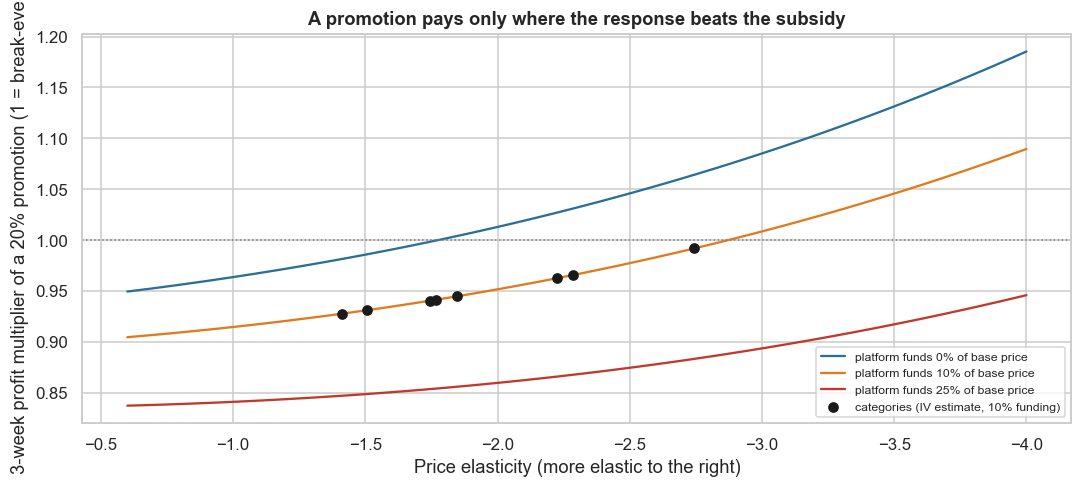

dip scaling r1 = -0.35, r2 = -0.16 | take rate 17% | funding 10% | scale: ₹30,000 crore GMV across the 8 categories
Break-even gross elasticity for a 20% promotion by funding share: 0%: -1.79, 10%: -2.88, 25%: -4.76
Categories where the base multiplier is below 1 (stop or move to seller funding): ['Apparel', 'Beauty', 'Books & stationery', 'Footwear', 'Home & kitchen', 'Mobile accessories', 'Mobiles', 'Small appliances']
Annual gain from stopping those promotions (₹ crore): worst (more elastic) 106, base 136, best (less elastic) 160


,promo share,avg depth,base GMV ₹ crore,IV elasticity,mult (base),mult (worst: more elastic),mult (best: less elastic),mult funding 0%,mult funding 25%,annual promo effect ₹ crore (base)
category,,,,,,,,,,
Apparel,0.1130,0.2440,"2,427.8300",-2.2260,0.9510,0.9720,0.9330,1.0410,0.8170,-6.8390
Beauty,0.1130,0.2440,"1,054.8140",-1.7460,0.9230,0.9390,0.9090,1.0010,0.8060,-4.6840
Books & stationery,0.1060,0.2460,"1,107.9570",-2.2870,0.9550,0.9720,0.9390,1.0470,0.8170,-2.6980
Footwear,0.1070,0.2430,"2,871.3400",-1.8480,0.9280,0.9470,0.9130,1.0080,0.8090,-11.2560
Home & kitchen,0.1140,0.2430,"1,850.1430",-1.7650,0.9240,0.9410,0.9100,1.0020,0.8070,-8.1660
Mobile accessories,0.1080,0.2420,"1,571.4910",-2.7420,0.9910,1.0130,0.9700,1.0920,0.8390,-0.8090
Mobiles,0.1130,0.2440,"15,704.7690",-1.4120,0.9070,0.9240,0.8940,0.9780,0.8010,-84.4790
Small appliances,0.1070,0.2450,"3,411.6560",-1.5070,0.9110,0.9260,0.8980,0.9840,0.8000,-16.6120


In [14]:
TAKE, FUND, ANNUAL_GMV = 0.17, 0.10, 30000e7
def mult(eps, delta, fund):
    L = np.asarray(eps, float) * np.log(1 - np.asarray(delta, float)); return (np.exp(L) * (TAKE * (1 - delta) - fund * delta) / TAKE + np.exp(R1 * L) + np.exp(R2 * L)) / 3
Dd = d0[d0.obs].copy(); Dd["gmv"] = Dd.price_inr * Dd.units; Dd["is_promo"] = Dd.sig_true == 1
cs = Dd.dropna(subset=["sig_true"]).groupby("category").apply(lambda x: pd.Series({"promo share": x.is_promo.mean(), "avg depth": x.loc[x.is_promo, "disc_true"].mean(), "base GMV": x.loc[~x.is_promo, "gmv"].mean() * 52 * x.sku_id.nunique()}))
cs["base GMV ₹ crore"] = cs["base GMV"] / cs["base GMV"].sum() * ANNUAL_GMV / 1e7
tb = cs.join(cat[["IV elasticity", "CI low", "CI high"]])
for lab_, e_ in (("mult (base)", tb["IV elasticity"]), ("mult (worst: more elastic)", tb["CI low"]), ("mult (best: less elastic)", tb["CI high"])): tb[lab_] = mult(e_, tb["avg depth"], FUND)
tb["mult funding 0%"] = mult(tb["IV elasticity"], tb["avg depth"], 0.0); tb["mult funding 25%"] = mult(tb["IV elasticity"], tb["avg depth"], 0.25)
tb["annual promo effect ₹ crore (base)"] = 3 * tb["promo share"] * TAKE * tb["base GMV ₹ crore"] * (tb["mult (base)"] - 1)
def gain(stop, col): return float((-3 * tb["promo share"] * TAKE * tb["base GMV ₹ crore"] * (tb[col] - 1))[stop].sum())
stop = tb["mult (base)"] < 1; sc_ = {"worst (more elastic)": gain(stop, "mult (worst: more elastic)"), "base": gain(stop, "mult (base)"), "best (less elastic)": gain(stop, "mult (best: less elastic)")}
grid = np.linspace(-0.5, -10, 400); be_eps = {f: (grid[np.argmax(mult(grid, 0.2, f) >= 1)] if (mult(grid, 0.2, f) >= 1).any() else np.nan) for f in (0.0, 0.10, 0.25)}
fig, ax = plt.subplots(figsize=(10, 4.6)); xs = np.linspace(-0.6, -4.0, 80)
for f, col in ((0.0, "#2a6f97"), (0.10, "#e07a1f"), (0.25, "#c0392b")): ax.plot(xs, mult(xs, 0.2, f), color=col, label=f"platform funds {f:.0%} of base price")
ax.scatter(tb["IV elasticity"], mult(tb["IV elasticity"], 0.2, FUND), color="k", zorder=3, label="categories (IV estimate, 10% funding)"); ax.axhline(1, color="grey", ls=":", lw=1); ax.invert_xaxis()
ax.set_xlabel("Price elasticity (more elastic to the right)"); ax.set_ylabel("3-week profit multiplier of a 20% promotion (1 = break-even)"); ax.set_title("A promotion pays only where the response beats the subsidy")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()
print(f"dip scaling r1 = {R1:.2f}, r2 = {R2:.2f} | take rate {TAKE:.0%} | funding {FUND:.0%} | scale: ₹{ANNUAL_GMV / 1e7:,.0f} crore GMV across the 8 categories")
print("Break-even gross elasticity for a 20% promotion by funding share: " + ", ".join((f"{f:.0%}: {v:.2f}" if not np.isnan(v) else f"{f:.0%}: none within -10") for f, v in be_eps.items()))
print(f"Categories where the base multiplier is below 1 (stop or move to seller funding): {list(tb.index[stop])}")
print("Annual gain from stopping those promotions (₹ crore): " + ", ".join(f"{k} {v:,.0f}" for k, v in sc_.items()))
tb[["promo share", "avg depth", "base GMV ₹ crore", "IV elasticity", "mult (base)", "mult (worst: more elastic)", "mult (best: less elastic)", "mult funding 0%", "mult funding 25%", "annual promo effect ₹ crore (base)"]].round(3)

**Takeaway (business reading):** With a 17% take rate and the platform funding 10% of the price cut, **no category earns back its promotion**: the three-week profit multiplier is **0.91 to 0.99** (mobile accessories 0.99, apparel 0.95, mobiles 0.91, small appliances 0.91). Mobile accessories reach 1.01 only at the elastic end of their CI. The break-even elasticity for a 20% promotion is **−1.79 with no platform funding, −2.88 at 10% funding and −4.76 at 25%**, so higher platform funding needs elasticities beyond anything seen here (−1.41 to −2.74). If sellers fund the discount (0% funding), six of eight categories are about break-even or slightly positive (multipliers 1.00 to 1.09) and mobiles (0.98) and small appliances (0.98) are slightly negative. Stopping the platform-funded promotions would add about **₹136 crore a year** (worst case ₹106 crore, best case ₹160 crore), with mobiles contributing most because of their GMV (₹15,705 crore of the ₹30,000 crore). These figures depend on assumed economics (take rate, funding share, GMV) and on a dip estimate that overstates the true dip, so the real gain may be smaller; **the ranking of categories is the more reliable result**. Acquisition value and ad revenue during sales are excluded, which favours discounts in reality.

## 10. Recommendation and Decision

**Recommendation**

1. **Stop using naive price-versus-units regressions** for pricing decisions. They gave −0.24 against a true −1.97. Estimate elasticity with an instrument (supplier cost shocks, here F = 5,658) and validate it in a randomised price test.
2. **Stop platform-funded promotions that cannot clear the break-even elasticity.** At 10% funding every category was below break-even; mobiles (elasticity −1.41, ₹15,705 crore of GMV) are the clearest case. Move these promotions to seller funding.
3. **Run elasticity-based price tests in the sale season**, starting with mobile accessories and apparel (most elastic), at about 90 SKUs for 8 weeks per category to get a CI half-width of 0.3.
4. **Do not use "% off MRP" as the quality test for a sale.** Use a discount against the SKU's own trailing 8-week median price (15% or more) and show or audit it separately from the displayed badge.
5. **Judge promotions on three-week net units and contribution after funding**, not on sale-week lift.

**Decision rule:** fund a promotion only if its 3-week profit multiplier (using the less elastic end of the category elasticity CI, the platform funding share and the measured dip) is at least 1; otherwise run it seller-funded or not at all.

**KPIs:** net three-week units (promotion week plus next two), contribution per ₹ of platform discount, share of badges that are real sales (today 23.8% of badge weeks), category elasticity and CI, experiment CI half-width.

**Not yet known:** real elasticities, whether the supplier-cost instrument is valid in real data, long-run reference-price effects, and the value of new customers won by sales.

## 11. Risks, Limitations and Next Steps

- **Weak evidence base.** Nothing here reproduces a company system. The one public paper is an outside study with no sales data; its 91.11% accuracy claim is not tested here. Treat every number as a property of the simulation.
- **Simulated elasticities and an assumed cost structure.** Category elasticities, the post-promotion dip, the take rate, the funding share and the ₹30,000 crore scale are assumptions. The ranking logic (naive is biased, IV and experiments are not) is robust; the rupee figures are not.
- **Instrument validity.** The exclusion restriction for the cost index is true by construction here. In real data, supplier cost shocks may coincide with quality or availability changes, and a single instrument cannot be tested. Always confirm with a randomised price test.
- **Local, short-run elasticities.** IV estimates the response of SKUs whose price moves with cost; the experiment covers only ±10% for 8 weeks. Extrapolating to deep sale discounts or to long-run reference-price effects is not supported.
- **Value left out.** New-customer acquisition, ad revenue during sales, competitor reaction and seller relationships are not in the profit multiplier.
- **Next steps:** run category-level price experiments in the sale season; build a reference-price rule for badges; estimate cross-price and cannibalisation effects between close substitutes; use bandits for price tests once the elasticity range is known.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Log-log elasticity | ε = d log units / d log price |
| Fixed-effects (within) estimator | demean y and x by SKU, then OLS |
| 2SLS | first stage: log price on controls + instrument; second stage: log units on fitted log price |
| Cluster-robust variance | (X'X)⁻¹ [Σ_g X_g' e_g e_g' X_g] (X'X)⁻¹ × G/(G−1), g = SKU |
| First-stage F | (instrument coefficient / SE)² for one instrument |
| Net 3-week promotion effect | mean(e^b0, e^b1, e^b2) − 1 |
| True discount | 1 − price / median(price over previous 8 weeks) |
| Displayed discount | 1 − price / MRP |
| Cohen's kappa | (observed agreement − chance agreement) / (1 − chance agreement) |
| 3-week profit multiplier | [e^L × (take (1−δ) − funding × δ) / take + e^(r1 L) + e^(r2 L)] / 3, L = ε ln(1−δ) |

| Term | Meaning |
|---|---|
| Price elasticity | % change in units per 1% change in price |
| Endogeneity | Price moves for reasons that also move demand |
| Instrument | A variable that moves price but touches demand only through price |
| MRP inflation | List price set high so the "% off" looks large |
| Pull-forward / dip | Sale-week units borrowed from the following weeks |
| Take rate | Platform revenue as a share of GMV |
| PR-AUC | Area under the precision-recall curve; its baseline is the prevalence |
| Holm | Step-down correction for multiple tests |